# Bloque C - C3: Máscara de regiones oscuras/violetas

**Objetivo:** construir, dentro de cada eritrocito, una **máscara de las zonas oscuras/violetas** donde puede estar el parásito.

**De dónde sale la idea:**
- En **C1** vimos que el parásito es "un punto oscuro y violeta dentro de un eritrocito rosado": se ve en los canales **G** (oscuro) y **b** de Lab (violeta).
- También vimos que el color *promedio* de la célula no alcanza, porque el parásito ocupa una parte chica.
- En **C2**, un umbral sobre el percentil 5 de la célula (`G_p5`) funcionó mal en pacientes nuevos (exactitud balanceada ≈0.63).

Acá en vez de resumir la célula en un número, **marcamos píxel por píxel** qué zonas son anormalmente oscuras/violetas y nos quedamos con las **manchas** (regiones conexas) de tamaño suficiente.

**Problema:** el GT marca la célula entera, no el parásito, así que **no tenemos píxeles de parásito etiquetados**. Por eso definimos "anormal" a partir de las **células sanas**: un píxel es sospechoso si es más oscuro/violeta que casi todos los píxeles de eritrocitos sanos de train.

**Regla del proyecto:** todo se ajusta **solo con train**, y los parámetros se eligen con validación **leave-one-patient-out** (como en C2). Las imágenes se normalizan con el **balance de blancos** recomendado en C2.

In [1]:
# BLOQUE C - C3: Máscara de regiones oscuras/violetas dentro de cada eritrocito

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

import itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from common.config import LABEL_PARASITIZED, LABEL_UNINFECTED
from common.io_utils import cargar_subset, cargar_imagen, cargar_gt
from segmentation.preprocess import mascara_circular

COLOR_MASCARA = np.array([0, 230, 120])  # verde para pintar la máscara sobre la imagen

## 1. Normalización y recortes de eritrocitos

Usamos la normalización por fondo de C2 (balance de blancos con referencia = promedio de train), importada de `color_stain/normalizacion.py`, el módulo que usa el pipeline y, para cada eritrocito del GT, guardamos su recorte normalizado con los canales **G** y **b**, y la máscara de la célula.

In [2]:
# Normalización por fondo: las mismas funciones que usa el pipeline (vienen de C2)
from color_stain.normalizacion import mediana_fondo, normalizar_fondo, cargar_referencia

imagenes = cargar_subset("train")
fondos = {}
for reg in imagenes:
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    fondos[reg["image_id"]] = mediana_fondo(img, mascara_circular(img))
fondo_ref = np.mean(list(fondos.values()), axis=0)
print("Fondo de referencia (R, G, B):", fondo_ref.round(1))
assert np.allclose(fondo_ref, cargar_referencia()), "La referencia no coincide con color_stain/results/referencia_fondo.json"

celulas = []
for reg in imagenes:
    img_cruda = cargar_imagen(reg["patient_id"], reg["image_id"])
    img = normalizar_fondo(img_cruda, fondos[reg["image_id"]], fondo_ref)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])

    for a in anot:
        if a["label"] not in [LABEL_UNINFECTED, LABEL_PARASITIZED] or a["polygon"] is None:
            continue
        poly = np.round(a["polygon"]).astype(np.int32)
        x0, y0 = np.maximum(poly.min(axis=0), 0)
        x1, y1 = poly.max(axis=0) + 1
        mascara = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
        cv2.fillPoly(mascara, [poly - [x0, y0]], 1)
        celulas.append({
            "patient_id": reg["patient_id"],
            "image_id": reg["image_id"],
            "label": a["label"],
            "rgb": img[y0:y1, x0:x1].copy(),
            "rgb_crudo": img_cruda[y0:y1, x0:x1].copy(),  # sin normalizar (para la validación de la sección 4)
            "G": img[y0:y1, x0:x1, 1].astype(np.int16),
            "b": lab[y0:y1, x0:x1, 2].astype(np.int16),
            "mascara": mascara,
            "centro": a["polygon"].mean(axis=0),
        })

pacientes = np.array([c["patient_id"] for c in celulas])
es_parasitada = np.array([c["label"] == LABEL_PARASITIZED for c in celulas])
print("Eritrocitos:", len(celulas), "| parasitadas:", es_parasitada.sum())

Fondo de referencia (R, G, B): [220.3 181.1 166.4]


Eritrocitos: 2352 | parasitadas: 217


## 2. Cómo se arma la máscara

Para cada eritrocito:
1. **(Opcional) Erosionamos** la máscara de la célula `E` píxeles. El borde del eritrocito es más oscuro que el centro y puede dar falsos positivos.
2. Tomamos el canal elegido (**G** para "oscuro" o **b** para "violeta"), de dos formas:
   - **absoluto:** el valor tal cual;
   - **relativo:** el valor menos la **mediana de la propia célula**. Así se compensa que algunas células o pacientes estén teñidos más fuerte (lo que vimos en C2).
3. Marcamos los píxeles **por debajo de un umbral** (en los dos canales, lo anormal es el valor *bajo*).
4. Nos quedamos solo con las **manchas de al menos `A` píxeles** (regiones conexas). Esto elimina ruido y puntitos sueltos.

**Cómo se elige el umbral:** es el percentil `q` de los píxeles de **eritrocitos sanos**. Con `q = 0.1`, solo el 0.1 % de los píxeles sanos queda marcado.

Una célula es **sospechosa** si su máscara final tiene al menos una mancha.

> **Importante:** las manchas de la máscara son **regiones sospechosas**, no parásitos verificados. Como el GT indica qué células están parasitadas pero no delimita cada parásito, no podemos medir si la mancha coincide exactamente con el parásito. Lo que sí evaluamos es si el método identifica las **células** que contienen regiones sospechosas.

In [3]:
def kernel_eliptico(radio):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radio + 1, 2 * radio + 1))


def valores_canal(celula, canal, modo, erosion):
    # Devuelve la máscara de la célula (erosionada) y el canal en valor absoluto o relativo a la mediana de la célula
    dentro = celula["mascara"]
    if erosion > 0:
        dentro = cv2.erode(dentro, kernel_eliptico(erosion))
    dentro = dentro > 0
    valores = celula[canal]
    if modo == "relativo":
        valores = valores - int(np.median(valores[dentro]))
    return dentro, valores


def mascara_oscura_violeta(celula, canal, modo, erosion, umbral, area_min):
    # Máscara final: píxeles por debajo del umbral, quedándonos solo con manchas de al menos area_min píxeles
    dentro, valores = valores_canal(celula, canal, modo, erosion)
    marcados = ((valores < umbral) & dentro).astype(np.uint8)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(marcados, connectivity=8)
    grandes = [k for k in range(1, n) if stats[k, cv2.CC_STAT_AREA] >= area_min]
    return np.isin(etiquetas, grandes)


def mayor_mancha(celula, canal, modo, erosion, umbral):
    # Área de la mancha más grande por debajo del umbral (0 si no hay ninguna)
    dentro, valores = valores_canal(celula, canal, modo, erosion)
    marcados = ((valores < umbral) & dentro).astype(np.uint8)
    n, _, stats, _ = cv2.connectedComponentsWithStats(marcados, connectivity=8)
    return stats[1:, cv2.CC_STAT_AREA].max() if n > 1 else 0

## 3. Elección de parámetros (leave-one-patient-out)

Probamos todas las combinaciones de:

| Parámetro | Valores |
|---|---|
| canal | G (oscuro), b (violeta) |
| modo | absoluto, relativo |
| erosión `E` | 0, 5 píxeles |
| percentil `q` de los sanos | 0.02, 0.05, 0.1, 0.2, 0.5 % |
| área mínima `A` | 25, 50, 100, 150, 200 píxeles |

Para cada combinación hacemos leave-one-patient-out: el umbral (percentil `q`) se calcula **solo con los sanos de los otros 5 pacientes**, y medimos la exactitud balanceada de "célula sospechosa" en el paciente que quedó afuera.

**Truco para que sea rápido:** en vez de juntar millones de píxeles cada vez, guardamos un **histograma por paciente** de los píxeles sanos. El percentil se saca sumando los histogramas de los pacientes de entrenamiento.

Como referencia, un eritrocito mide ≈14000 píxeles (≈130 px de diámetro).

In [4]:
CANALES_C3 = ["G", "b"]
MODOS = ["absoluto", "relativo"]
EROSIONES = [0, 5]
PERCENTILES = [0.02, 0.05, 0.1, 0.2, 0.5]
AREAS = [25, 50, 100, 150, 200]

DESPLAZAMIENTO = 255  # los valores relativos van de -255 a 255; los corremos para usarlos como índice del histograma


def histogramas_sanos(lista, canal, modo, erosion):
    # Un histograma por paciente con los píxeles de eritrocitos sanos
    hist = {p: np.zeros(511, dtype=np.int64) for p in sorted({c["patient_id"] for c in lista})}
    for c in lista:
        if c["label"] != LABEL_UNINFECTED:
            continue
        dentro, valores = valores_canal(c, canal, modo, erosion)
        hist[c["patient_id"]] += np.bincount(valores[dentro] + DESPLAZAMIENTO, minlength=511)
    return hist


def percentil_desde_histograma(hist, q):
    acumulado = np.cumsum(hist) / hist.sum()
    return np.searchsorted(acumulado, q / 100) - DESPLAZAMIENTO  # primer valor que deja q % por debajo


def exactitud_balanceada(es_positivo, prediccion):
    return (prediccion[es_positivo].mean() + (~prediccion[~es_positivo]).mean()) / 2


def busqueda_lopo(lista):
    # Prueba todas las combinaciones con leave-one-patient-out sobre las células de "lista"
    pac = np.array([c["patient_id"] for c in lista])
    y = np.array([c["label"] == LABEL_PARASITIZED for c in lista])
    filas = []
    for canal, modo, erosion in itertools.product(CANALES_C3, MODOS, EROSIONES):
        hist = histogramas_sanos(lista, canal, modo, erosion)
        for q in PERCENTILES:
            # Para cada paciente: umbral con los demás, y área de la mayor mancha de cada una de sus células
            areas = np.zeros(len(lista))
            for paciente in hist:
                umbral = percentil_desde_histograma(sum(h for p, h in hist.items() if p != paciente), q)
                for i in np.nonzero(pac == paciente)[0]:
                    areas[i] = mayor_mancha(lista[i], canal, modo, erosion, umbral)

            for area_min in AREAS:
                sospechosa = areas >= area_min
                por_paciente = [exactitud_balanceada(y[pac == p], sospechosa[pac == p]) for p in hist]
                filas.append({
                    "canal": canal, "modo": modo, "E": erosion, "q (%)": q, "A": area_min,
                    "exactitud bal. (media)": np.mean(por_paciente),
                    "exactitud bal. (peor paciente)": np.min(por_paciente),
                    "sensibilidad": sospechosa[y].mean(),
                    "especificidad": (~sospechosa[~y]).mean(),
                })
    return pd.DataFrame(filas).sort_values("exactitud bal. (media)", ascending=False, kind="stable")


busqueda = busqueda_lopo(celulas)
busqueda.head(15).round(3)

,canal,modo,E,q (%),A,exactitud bal. (media),exactitud bal. (peor paciente),sensibilidad,especificidad
81,G,relativo,5,0.05,50,0.957,0.778,0.982,0.979
56,G,relativo,0,0.05,50,0.956,0.776,0.982,0.977
80,G,relativo,5,0.05,25,0.952,0.771,0.982,0.970
62,G,relativo,0,0.10,100,0.952,0.783,0.982,0.970
181,b,relativo,5,0.05,50,0.952,0.788,0.926,0.985
30,G,absoluto,5,0.05,25,0.951,0.777,0.986,0.971
180,b,relativo,5,0.05,25,0.950,0.781,0.935,0.979
5,G,absoluto,0,0.05,25,0.950,0.774,0.986,0.969
55,G,relativo,0,0.05,25,0.950,0.769,0.986,0.964
187,b,relativo,5,0.10,100,0.948,0.788,0.931,0.976


Para ver el efecto de cada decisión por separado, mostramos **la mejor combinación** dentro de cada opción:

In [5]:
columnas = ["exactitud bal. (media)", "exactitud bal. (peor paciente)"]
pd.concat({
    parametro: busqueda.loc[busqueda.groupby(parametro)["exactitud bal. (media)"].idxmax()].set_index(parametro)[columnas]
    for parametro in ["canal", "modo", "E"]
}).round(3)

exactitud bal. (media)  exactitud bal. (peor paciente)
canal G                          0.957                           0.778
      b                          0.952                           0.788
modo  absoluto                   0.951                           0.777
      relativo                   0.957                           0.778
E     0                          0.956                           0.776
      5                          0.957                           0.778

**Qué se ve:**
- Con la máscara la detección mejora **muchísimo** respecto de C2: la exactitud balanceada en un paciente nuevo pasa de ≈0.63 (umbral sobre `G_p5`) a más de 0.9. Tiene sentido: `G_p5` mezcla el parásito con ~700 píxeles del resto de la célula, mientras que la máscara busca directamente una **mancha compacta** oscura.
- Los mejores resultados aparecen con un percentil `q` **muy bajo** (0.05 %: umbral muy estricto) y un **área mínima** de unos 50 píxeles: el parásito es claramente más oscuro que casi cualquier zona de una célula sana y forma una mancha de tamaño apreciable.
- **G** (oscuro) y **b** (violeta) dan resultados muy parecidos (0.957 vs 0.952). **Relativo** queda apenas mejor que absoluto, y **erosionar** el borde da prácticamente lo mismo. Son diferencias chicas, dentro del ruido.
- El **peor paciente** queda bastante más abajo que la media; son pacientes con muy pocas parasitadas (4-5), donde una sola célula mal clasificada cambia mucho el resultado.

> **Ojo:** esta búsqueda es **exploratoria**. La mejor combinación se elige mirando esta misma validación, así que su exactitud (0.957) está inflada: es la mejor de 200 intentos sobre los mismos pacientes. Además, la referencia de normalización incluye a todos los pacientes. Para tener una estimación honesta, en la sección 4 hacemos una **validación anidada**.

## 4. Validación anidada por paciente

Para estimar cómo funciona el método en un **paciente realmente nuevo**, repetimos todo el proceso de elección **sin mirar al paciente que queda afuera**:

Para cada uno de los 6 pacientes de train:
1. Lo dejamos afuera.
2. Calculamos la **referencia de normalización** solo con los otros 5 y renormalizamos los recortes.
3. Elegimos los **parámetros** con la misma búsqueda de la sección 3 (200 combinaciones, leave-one-patient-out), pero **solo sobre los otros 5**.
4. Calculamos el **umbral** con los sanos de esos 5.
5. Aplicamos la máscara al paciente que quedó afuera y medimos su exactitud balanceada.

El paciente de afuera no interviene en ninguna decisión, así que su resultado es una estimación honesta. Si además los parámetros elegidos son parecidos en cada vuelta, el método es **estable**.

> **Limitación:** el aislamiento es completo en la partición **externa**. En la búsqueda **interna** (sobre los otros 5 pacientes) se usa la referencia de esos 5, sin recalcularla en cada subdivisión. Hacerlo sería una mejora opcional; como el detector usa G con balance de blancos, donde cambiar la referencia casi no influye (C2), no esperamos que cambie el resultado.

In [6]:
def recortes_normalizados(ref):
    # Copia de las células con G y b recalculados a partir del recorte crudo, normalizando con otra referencia
    nuevas = []
    for c in celulas:
        rgb = normalizar_fondo(c["rgb_crudo"], fondos[c["image_id"]], ref)
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        nuevas.append({**c, "G": rgb[:, :, 1].astype(np.int16), "b": lab[:, :, 2].astype(np.int16)})
    return nuevas


filas_anidada = []
for paciente in sorted(set(pacientes)):
    # 1-2. Referencia sin el paciente y recortes renormalizados
    ref_sin = np.mean([fondos[r["image_id"]] for r in imagenes if r["patient_id"] != paciente], axis=0)
    lista = recortes_normalizados(ref_sin)
    entreno = [c for c in lista if c["patient_id"] != paciente]
    prueba = [c for c in lista if c["patient_id"] == paciente]

    # 3. Parámetros elegidos solo con los otros 5 pacientes
    elegida = busqueda_lopo(entreno).iloc[0]
    canal, modo, erosion = elegida["canal"], elegida["modo"], int(elegida["E"])

    # 4. Umbral con los sanos de los otros 5
    umbral = int(percentil_desde_histograma(sum(histogramas_sanos(entreno, canal, modo, erosion).values()), elegida["q (%)"]))

    # 5. Evaluación en el paciente que quedó afuera
    y_prueba = np.array([c["label"] == LABEL_PARASITIZED for c in prueba])
    sospechosa_prueba = np.array([mayor_mancha(c, canal, modo, erosion, umbral) >= elegida["A"] for c in prueba])
    filas_anidada.append({
        "paciente": paciente,
        "parasitadas": y_prueba.sum(),
        "sanas": (~y_prueba).sum(),
        "canal": canal, "modo": modo, "E": erosion, "q (%)": elegida["q (%)"], "A": int(elegida["A"]),
        "umbral": umbral,
        "sensibilidad": sospechosa_prueba[y_prueba].mean(),
        "especificidad": (~sospechosa_prueba[~y_prueba]).mean(),
        "exactitud balanceada": exactitud_balanceada(y_prueba, sospechosa_prueba),
    })

anidada = pd.DataFrame(filas_anidada)
print("Exactitud balanceada (media de los 6 pacientes): {:.3f}".format(anidada["exactitud balanceada"].mean()))
print("Exactitud balanceada (peor paciente):            {:.3f}".format(anidada["exactitud balanceada"].min()))
anidada.round(3)

Exactitud balanceada (media de los 6 pacientes): 0.951
Exactitud balanceada (peor paciente):            0.789


,paciente,parasitadas,sanas,canal,modo,E,q (%),A,umbral,sensibilidad,especificidad,exactitud balanceada
0,208C67P28N_ThinF,21,457,G,relativo,0,0.05,25,-44,1.000,0.974,0.987
1,209C68P29N_ThinF,145,268,G,absoluto,0,0.05,25,106,0.993,0.899,0.946
2,211C70P31_ThinF,37,193,G,relativo,5,0.05,50,-40,1.000,0.990,0.995
3,212C71P32_ThinF,5,496,G,relativo,5,0.05,50,-41,1.000,0.984,0.992
4,263C115P76ThinF,5,486,G,relativo,5,0.02,25,-52,0.600,0.977,0.789
5,282C134P95ThinF,4,235,G,relativo,5,0.05,50,-42,1.000,1.000,1.000


**Qué se ve:**
- **La estimación honesta es casi igual a la exploratoria:** exactitud balanceada media **0.951** con validación anidada, contra 0.957 de la búsqueda de la sección 3. O sea, elegir la mejor de 200 combinaciones casi no infló el resultado: el método no depende de un ajuste fino de los parámetros.
- **Los parámetros son estables:** en las 6 vueltas se eligió el canal **G**, en 5 de 6 el modo **relativo** y en 5 de 6 `q` = 0.05 %. El umbral relativo queda entre −40 y −52, y el área mínima entre 25 y 50 píxeles.
- **El peor paciente es 263C115P76** (0.789): de sus 5 parasitadas detecta 3. Con tan pocas células, cada una pesa un 20 % de la sensibilidad.
- **El paciente 209C68P29N** (el de más parasitadas) tiene la especificidad más baja (0.90): sus células son más oscuras en general (lo vimos en C2), y en esa vuelta se eligió el modo absoluto.

## 5. Parámetros finales

Nos quedamos con la mejor combinación y calculamos el umbral definitivo con **todos los pacientes de train**. Estos son los valores que se le pasan a C4 y al Bloque A.

In [7]:
mejor = busqueda.iloc[0]
PARAMS = {"canal": mejor["canal"], "modo": mejor["modo"], "erosion": int(mejor["E"]), "area_min": int(mejor["A"])}
hist = histogramas_sanos(celulas, PARAMS["canal"], PARAMS["modo"], PARAMS["erosion"])
PARAMS["umbral"] = int(percentil_desde_histograma(sum(hist.values()), mejor["q (%)"]))

print("Parámetros elegidos (q = {} %):".format(mejor["q (%)"]))
for k, v in PARAMS.items():
    print(f"  {k}: {v}")

# Máscara y resultado para todas las células de train con los parámetros finales
for c in celulas:
    c["mascara_c3"] = mascara_oscura_violeta(c, **PARAMS)
sospechosa = np.array([c["mascara_c3"].any() for c in celulas])

resumen_final = pd.DataFrame({
    "células": pd.Series(es_parasitada).map({True: LABEL_PARASITIZED, False: LABEL_UNINFECTED}),
    "sospechosa": sospechosa,
}).value_counts().unstack(fill_value=0)
resumen_final

Parámetros elegidos (q = 0.05 %):
  canal: G
  modo: relativo
  erosion: 5
  area_min: 50
  umbral: -39


sospechosa,True,False
células,,
Parasitized,213,4
Uninfected,40,2095


## 6. Cómo se ve la máscara

Pintamos la máscara en **verde** sobre algunas células de train: aciertos y errores de cada clase. Mirar los errores ayuda a entender qué confunde a la máscara.

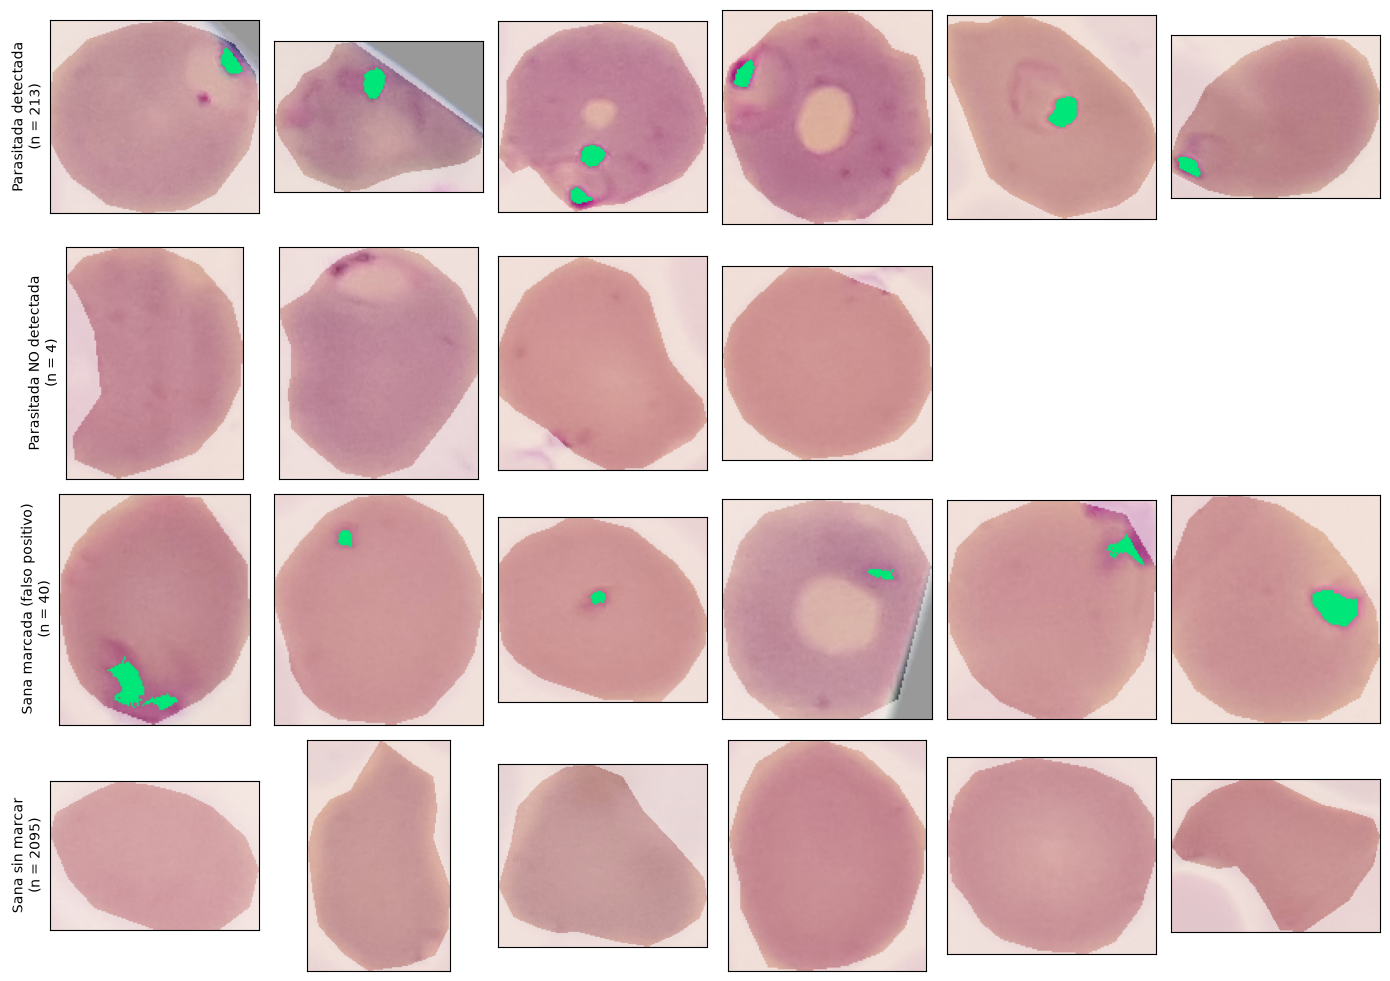

In [8]:
def pintar(celula):
    # Recorte RGB con el fondo fuera de la célula aclarado y la máscara C3 en verde
    img = celula["rgb"].copy()
    img[celula["mascara"] == 0] = (img[celula["mascara"] == 0] * 0.4 + 255 * 0.6).astype(np.uint8)
    img[celula["mascara_c3"]] = COLOR_MASCARA
    return img


rng = np.random.default_rng(0)
grupos = {
    "Parasitada detectada": np.nonzero(es_parasitada & sospechosa)[0],
    "Parasitada NO detectada": np.nonzero(es_parasitada & ~sospechosa)[0],
    "Sana marcada (falso positivo)": np.nonzero(~es_parasitada & sospechosa)[0],
    "Sana sin marcar": np.nonzero(~es_parasitada & ~sospechosa)[0],
}
n_por_grupo = 6

fig, ax = plt.subplots(len(grupos), n_por_grupo, figsize=(14, 10))
for fila, (nombre, indices) in enumerate(grupos.items()):
    elegidos = rng.choice(indices, size=min(n_por_grupo, len(indices)), replace=False) if len(indices) else []
    for col in range(n_por_grupo):
        eje = ax[fila, col]
        eje.set_xticks([])
        eje.set_yticks([])
        if col < len(elegidos):
            eje.imshow(pintar(celulas[elegidos[col]]))
        else:
            eje.axis("off")
    ax[fila, 0].set_ylabel(f"{nombre}\n(n = {len(indices)})", fontsize=10)
plt.tight_layout()
plt.show()

Y sobre una zona de una imagen completa, para ver la máscara en contexto (solo dentro de los eritrocitos del GT):

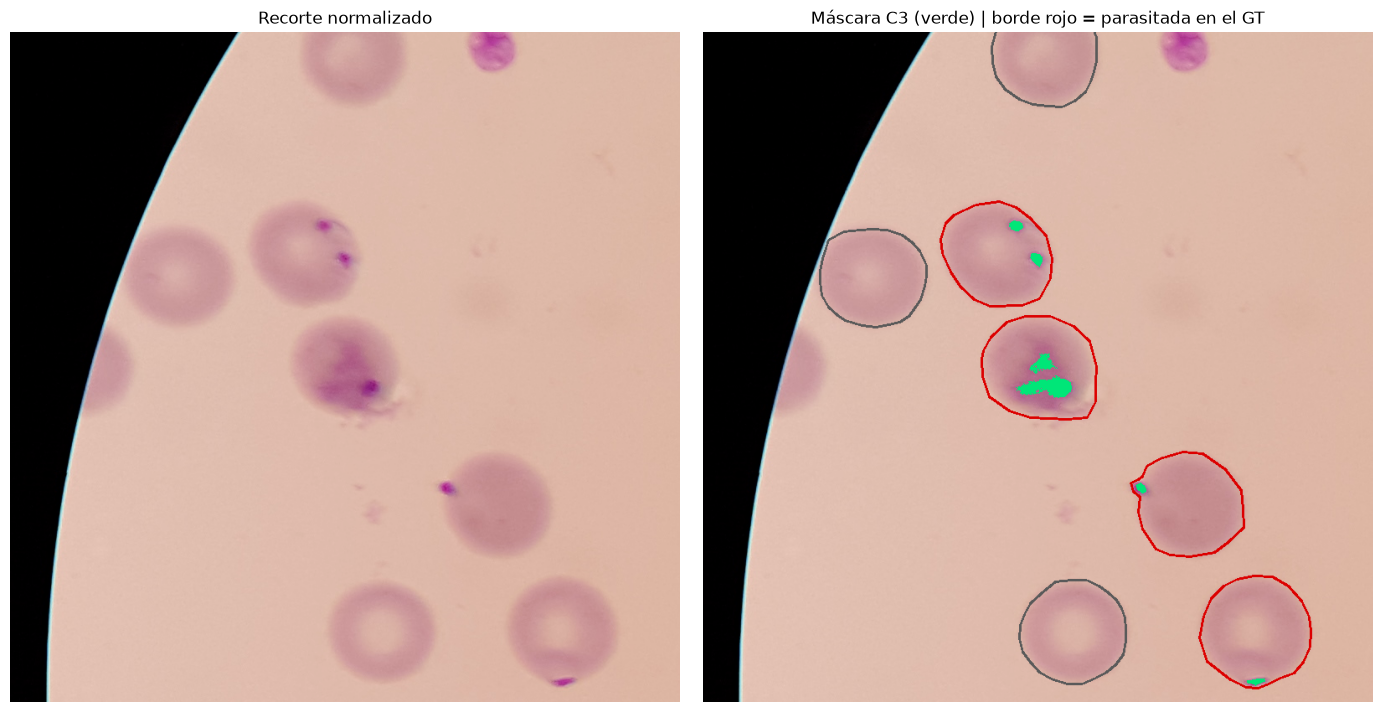

In [9]:
# Zona alrededor de la parasitada detectada con la mancha más grande
k = max(grupos["Parasitada detectada"], key=lambda i: celulas[i]["mascara_c3"].sum())
reg = next(r for r in imagenes if r["image_id"] == celulas[k]["image_id"])
img = normalizar_fondo(cargar_imagen(reg["patient_id"], reg["image_id"]), fondos[reg["image_id"]], fondo_ref)
anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])

pintada = img.copy()
for a in anot:
    if a["label"] not in [LABEL_UNINFECTED, LABEL_PARASITIZED] or a["polygon"] is None:
        continue
    poly = np.round(a["polygon"]).astype(np.int32)
    x0, y0 = np.maximum(poly.min(axis=0), 0)
    x1, y1 = poly.max(axis=0) + 1
    mascara = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
    cv2.fillPoly(mascara, [poly - [x0, y0]], 1)
    lab = cv2.cvtColor(img[y0:y1, x0:x1], cv2.COLOR_RGB2LAB)
    celula = {"G": img[y0:y1, x0:x1, 1].astype(np.int16), "b": lab[:, :, 2].astype(np.int16), "mascara": mascara}
    pintada[y0:y1, x0:x1][mascara_oscura_violeta(celula, **PARAMS)] = COLOR_MASCARA
    color_borde = (220, 0, 0) if a["label"] == LABEL_PARASITIZED else (90, 90, 90)
    cv2.polylines(pintada, [poly], True, color_borde, 2)

centro = celulas[k]["centro"].astype(int)
mitad = 400
y0, x0 = np.maximum(centro[::-1] - mitad, 0)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(img[y0:y0 + 2 * mitad, x0:x0 + 2 * mitad])
ax[0].set_title("Recorte normalizado")
ax[1].imshow(pintada[y0:y0 + 2 * mitad, x0:x0 + 2 * mitad])
ax[1].set_title("Máscara C3 (verde) | borde rojo = parasitada en el GT")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## 7. Regiones candidatas en la imagen completa (para el Bloque A)

Todo lo anterior parte de células **ya delimitadas** con los polígonos del GT: la regla compara cada píxel con la mediana **de su célula**. Pero en la **segmentación dirigida por color** (procedimiento A, tarea A6) todavía no se conocen las células: C tiene que entregar **regiones candidatas detectadas directamente en la imagen**, y A después busca el eritrocito que contiene cada una.

Para eso necesitamos un detector que funcione sobre la imagen completa y **no use el GT**. El GT solo se usa en train para elegir los parámetros y para evaluar.

**Idea: top-hat negro.** Es una operación morfológica: `top-hat negro = cierre(G) − G`.
- El **cierre** con un disco de radio `r` "rellena" las zonas oscuras **más chicas que el disco** con el valor de su entorno.
- Restándole la imagen original, quedan resaltadas **solo las manchas oscuras chicas**, con un valor igual a cuánto más oscuras son que lo que las rodea.
- Un eritrocito entero (≈130 px de diámetro) es más grande que el disco, así que no se resalta; un parásito (≈10-30 px) sí.

Es el equivalente, sin conocer la célula, de lo que hacíamos antes con "G menos la mediana de la célula".

**Pasos del detector:**
1. Normalizar por fondo (referencia de train, como en C2).
2. Calcular el top-hat negro de G con un disco de radio `r`.
3. Marcar los píxeles con top-hat mayor a un umbral. El umbral se elige igual que antes: deja marcado solo un `q` % de los píxeles de **eritrocitos sanos** de train.
4. **Excluir glóbulos blancos** (ver abajo).
5. (Opcional) Quedarse solo con la **zona de células**: Otsu sobre G (lo mismo que hace el Bloque A) dilatado 10 píxeles. Esto elimina manchas sueltas en el fondo, como plaquetas o suciedad.
6. Quedarse con las manchas de al menos `A` píxeles.

**Glóbulos blancos.** El núcleo del glóbulo blanco es más grande que el disco, así que el top-hat casi no lo marca, pero su borde sí. Para separarlos usamos el **mismo criterio que el pipeline** (`color_stain/wbc_detection.py`, función `detectar_wbc`):
- **violeta:** b < 127 (de C1, umbral de Youden para separar WBC de eritrocitos);
- **y oscuro:** G < 100 (de C1, el núcleo tiene G ≈ 52, mientras que el 95 % de los píxeles de parasitadas tiene G > 124);
- apertura de radio 3 para limpiar puntitos, y nos quedamos con las regiones de **al menos 6000 píxeles**.

En una primera versión usábamos solo "violeta" (b < 127) con un área mínima de 12000 píxeles. Al probarla sobre la segmentación de train, en el paciente 209C68P29N (el de tinción más oscura) también marcaba eritrocitos y se perdían 3 células parasitadas. Pedir además que sea **oscuro** lo corrige.

Importamos los umbrales de `wbc_detection.py` en vez de llamar directamente a `detectar_wbc`, porque `detectar_wbc` siempre normaliza con la referencia de todo train, y en la validación anidada cada vuelta usa su propia referencia (sin el paciente evaluado). Más abajo comprobamos que, con la referencia de train, las dos dan **exactamente la misma máscara**.

Esta máscara marca el **núcleo** (no el citoplasma) y es un **aporte para la tarea A3**: el Bloque A elimina el objeto segmentado entero que contiene cada núcleo. Acá la usamos para que esas regiones no cuenten como candidatas a parásito.

In [10]:
from common.generar_gt_utils import mapa_gt
from common.config import LABEL_WBC

# Criterio de glóbulos blancos: el mismo que usa el pipeline (b < 127, G < 100, apertura de radio 3, área >= 6000)
from color_stain.wbc_detection import UMBRAL_B_WBC, UMBRAL_G_WBC, AREA_MIN_WBC, RADIO_APERTURA, detectar_wbc

TOPHAT_MIN = 15        # solo guardamos píxeles con top-hat > 15 (los umbrales que se prueban son siempre mayores)


def tophat_negro(verde, radio):
    return cv2.morphologyEx(verde, cv2.MORPH_BLACKHAT, kernel_eliptico(radio))


def zona_celulas(verde, campo, margen=10):
    # Zona de células sin GT: Otsu sobre G dentro del campo (las células son más oscuras que el fondo), dilatada
    umbral, _ = cv2.threshold(verde[campo].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.dilate(((verde <= umbral) & campo).astype(np.uint8), kernel_eliptico(margen)) > 0


def componentes(marcados):
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(marcados.astype(np.uint8), connectivity=8)
    return n, etiquetas, stats[:, cv2.CC_STAT_AREA]


def mascara_wbc(imagen_norm, campo):
    # Núcleos de glóbulos blancos: violetas Y oscuros, en regiones grandes (misma lógica que detectar_wbc,
    # pero sobre una imagen ya normalizada, para poder usar otra referencia en la validación anidada)
    b = cv2.cvtColor(imagen_norm, cv2.COLOR_RGB2LAB)[:, :, 2]
    candidatos = (b < UMBRAL_B_WBC) & (imagen_norm[:, :, 1] < UMBRAL_G_WBC) & campo
    candidatos = cv2.morphologyEx(candidatos.astype(np.uint8), cv2.MORPH_OPEN, kernel_eliptico(RADIO_APERTURA))
    n, etiquetas, areas = componentes(candidatos)
    return np.isin(etiquetas, [k for k in range(1, n) if areas[k] >= AREA_MIN_WBC])


def regiones_candidatas(imagen_norm, radio, umbral, area_min, solo_celulas):
    # Detector final sobre la imagen completa (no usa GT). Devuelve (máscara de candidatas a parásito, máscara de WBC)
    verde = imagen_norm[:, :, 1]
    campo = mascara_circular(imagen_norm)
    wbc = mascara_wbc(imagen_norm, campo)
    marcados = (tophat_negro(verde, radio) > umbral) & campo & ~wbc
    if solo_celulas:
        marcados &= zona_celulas(verde, campo)
    n, etiquetas, areas = componentes(marcados)
    return np.isin(etiquetas, [k for k in range(1, n) if areas[k] >= area_min]), wbc


# Comprobación: con la referencia de train, mascara_wbc da exactamente lo mismo que detectar_wbc (la del pipeline)
reg = next(r for r in imagenes if r["image_id"] == "IMG_20150819_133447.jpg")  # imagen con 3 glóbulos blancos
img_cruda = cargar_imagen(reg["patient_id"], reg["image_id"])
campo_crudo = mascara_circular(img_cruda)
igual = np.array_equal(mascara_wbc(normalizar_fondo(img_cruda, fondos[reg["image_id"]], fondo_ref), campo_crudo),
                       detectar_wbc(img_cruda, campo_crudo))
print("¿mascara_wbc coincide con detectar_wbc?", igual)
assert igual

¿mascara_wbc coincide con detectar_wbc? True


### Preparación (train)

Para cada imagen de train y cada radio calculamos el top-hat una sola vez y guardamos:
- un **histograma por paciente** del top-hat en los píxeles de **eritrocitos sanos** (para elegir umbrales);
- los píxeles "sospechosos" (top-hat > 15), indicando si están en la zona de células y a qué célula del GT pertenecen (solo para evaluar).

Así cada combinación de parámetros se evalúa sin recalcular el top-hat. Todo esto depende de la **referencia de normalización**, así que lo armamos con una función `preparar_datos(ref)`: en la búsqueda exploratoria se usa la referencia de todo train, y en la validación anidada se vuelve a preparar con la referencia **sin el paciente evaluado**.

In [11]:
RADIOS = [10, 15, 20]


def preparar_datos(ref):
    # Normaliza las 12 imágenes de train con la referencia "ref" y guarda lo necesario para elegir parámetros y evaluar
    hist = {(p, r): np.zeros(256, dtype=np.int64) for p in set(pacientes) for r in RADIOS}
    imgs = {}
    wbc_eval = {"WBC en el GT": 0, "WBC cubiertos": 0, "regiones que no son WBC": 0}
    for reg in imagenes:
        img = normalizar_fondo(cargar_imagen(reg["patient_id"], reg["image_id"]), fondos[reg["image_id"]], ref)
        verde = img[:, :, 1]
        campo = mascara_circular(img)
        wbc = mascara_wbc(img, campo)
        zona = zona_celulas(verde, campo)

        # GT: solo para elegir umbrales y evaluar
        anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
        mapa = mapa_gt(img.shape, anot)
        etiquetas_gt = {k: a["label"] for k, a in enumerate(anot, start=1)}
        sanos = np.isin(mapa, [k for k, l in etiquetas_gt.items() if l == LABEL_UNINFECTED])

        # Evaluación de la máscara de WBC (sobre los mismos datos con los que se eligió el área mínima)
        n_w, etiquetas_w, _ = componentes(wbc)
        for k in range(1, n_w):
            ids, cuentas = np.unique(mapa[etiquetas_w == k], return_counts=True)
            wbc_eval["regiones que no son WBC"] += etiquetas_gt.get(ids[np.argmax(cuentas)]) != LABEL_WBC
        for k, l in etiquetas_gt.items():
            if l == LABEL_WBC:
                wbc_eval["WBC en el GT"] += 1
                wbc_eval["WBC cubiertos"] += (wbc & (mapa == k)).sum() > 0.3 * (mapa == k).sum()  # más del 30 % de su área

        por_radio = {}
        for r in RADIOS:
            th = tophat_negro(verde, r)
            hist[(reg["patient_id"], r)] += np.bincount(th[sanos], minlength=256)
            idx = np.flatnonzero((th > TOPHAT_MIN) & campo & ~wbc)
            por_radio[r] = {"idx": idx, "valor": th.ravel()[idx], "en_zona": zona.ravel()[idx], "celda": mapa.ravel()[idx]}

        imgs[reg["image_id"]] = {"paciente": reg["patient_id"], "forma": verde.shape, "por_radio": por_radio,
                                 "etiquetas_gt": etiquetas_gt}
    return {"hist": hist, "imgs": imgs, "wbc_eval": wbc_eval, "cache": {}}


datos_comun = preparar_datos(fondo_ref)
print("Imágenes preparadas:", len(datos_comun["imgs"]))
print("Máscara de WBC en train:", datos_comun["wbc_eval"])

Imágenes preparadas: 12
Máscara de WBC en train: {'WBC en el GT': 10, 'WBC cubiertos': np.int64(10), 'regiones que no son WBC': 0}


### Evaluación de una combinación de parámetros

Para cada imagen, cada mancha candidata se asigna a la célula del GT que contiene **la mayoría de sus píxeles** (o al fondo, si no cae en ninguna). Medimos por paciente:
- **Sensibilidad:** proporción de eritrocitos **parasitados** que contienen al menos una candidata.
- **Especificidad:** proporción de eritrocitos **sanos** sin ninguna candidata.
- **Exactitud balanceada** = (sensibilidad + especificidad) / 2, como en las secciones anteriores.
- **Candidatas en el fondo por imagen:** manchas que no caen en ningún eritrocito. Para A6 son falsos positivos (A buscaría una célula que no está).

Los parámetros se eligen por exactitud balanceada; ante empate (a 3 decimales), gana la que deja menos candidatas en el fondo.

In [12]:
Q_TOPHAT = [0.01, 0.02, 0.05, 0.1]  # % de píxeles sanos que quedan por encima del umbral
AREAS_IMG = [25, 50, 100]
SOLO_CELULAS = [False, True]


def umbral_tophat(datos, lista_pacientes, radio, q):
    hist = sum(datos["hist"][(p, radio)] for p in lista_pacientes)
    acumulado = np.cumsum(hist) / hist.sum()
    umbral = int(np.searchsorted(acumulado, 1 - q / 100))  # top-hat > umbral deja como mucho q % de sanos
    assert umbral >= TOPHAT_MIN
    return umbral


def manchas_imagen(datos, iid, radio, umbral, solo_celulas):
    # Área de cada mancha y célula del GT a la que pertenece (0 = fondo). Se guarda en caché.
    clave = (iid, radio, umbral, solo_celulas)
    if clave not in datos["cache"]:
        d = datos["imgs"][iid]
        r = d["por_radio"][radio]
        sel = r["valor"] > umbral
        if solo_celulas:
            sel &= r["en_zona"]
        marcados = np.zeros(d["forma"][0] * d["forma"][1], dtype=np.uint8)
        marcados[r["idx"][sel]] = 1
        n, etiquetas, areas = componentes(marcados.reshape(d["forma"]))
        comp = etiquetas.ravel()[r["idx"][sel]].astype(np.int64)
        celda = r["celda"][sel].astype(np.int64)
        # Célula mayoritaria de cada mancha
        pares, cuentas = np.unique(comp * 100000 + celda, return_counts=True)
        c_comp, c_celda = pares // 100000, pares % 100000
        orden = np.lexsort((-cuentas, c_comp))
        primero = orden[np.unique(c_comp[orden], return_index=True)[1]]
        datos["cache"][clave] = pd.DataFrame({"area": areas[c_comp[primero]], "celda": c_celda[primero]})
    return datos["cache"][clave]


def evaluar_paciente(datos, paciente, radio, umbral, area_min, solo_celulas):
    tp = fn = fp = tn = fondo = n_img = 0
    for iid, d in datos["imgs"].items():
        if d["paciente"] != paciente:
            continue
        m = manchas_imagen(datos, iid, radio, umbral, solo_celulas)
        m = m[m["area"] >= area_min]
        con_candidata = set(m["celda"]) - {0}
        for k, label in d["etiquetas_gt"].items():
            if label == LABEL_PARASITIZED:
                tp += k in con_candidata
                fn += k not in con_candidata
            elif label == LABEL_UNINFECTED:
                fp += k in con_candidata
                tn += k not in con_candidata
        fondo += (m["celda"] == 0).sum()
        n_img += 1
    sens, espec = tp / (tp + fn), tn / (tn + fp)
    return {"sensibilidad": sens, "especificidad": espec, "exactitud balanceada": (sens + espec) / 2,
            "candidatas en fondo por imagen": fondo / n_img}


def busqueda_imagen(datos, lista_pacientes):
    # Leave-one-patient-out sobre lista_pacientes para todas las combinaciones
    filas = []
    for radio, q, solo, area_min in itertools.product(RADIOS, Q_TOPHAT, SOLO_CELULAS, AREAS_IMG):
        res = [evaluar_paciente(datos, p, radio, umbral_tophat(datos, [o for o in lista_pacientes if o != p], radio, q),
                                area_min, solo)
               for p in lista_pacientes]
        res = pd.DataFrame(res)
        filas.append({"radio": radio, "q (%)": q, "solo células": solo, "A": area_min,
                      "exactitud bal. (media)": res["exactitud balanceada"].mean(),
                      "exactitud bal. (peor paciente)": res["exactitud balanceada"].min(),
                      "sensibilidad (media)": res["sensibilidad"].mean(),
                      "especificidad (media)": res["especificidad"].mean(),
                      "candidatas en fondo por imagen": res["candidatas en fondo por imagen"].mean()})
    tabla = pd.DataFrame(filas)
    tabla["_orden"] = tabla["exactitud bal. (media)"].round(3)
    return tabla.sort_values(["_orden", "candidatas en fondo por imagen"], ascending=[False, True]).drop(columns="_orden")


pacientes_train = sorted(set(pacientes))
busqueda_img = busqueda_imagen(datos_comun, pacientes_train)
busqueda_img.head(10).round(3)

,radio,q (%),solo células,A,exactitud bal. (media),exactitud bal. (peor paciente),sensibilidad (media),especificidad (media),candidatas en fondo por imagen
54,20,0.02,False,25,0.954,0.791,0.922,0.985,7.500
57,20,0.02,True,25,0.954,0.791,0.922,0.985,7.500
30,15,0.02,False,25,0.953,0.791,0.922,0.985,6.583
33,15,0.02,True,25,0.953,0.791,0.922,0.985,6.583
13,10,0.05,False,50,0.948,0.779,0.922,0.974,8.917
16,10,0.05,True,50,0.948,0.779,0.922,0.974,8.917
23,10,0.10,True,100,0.948,0.783,0.922,0.974,9.583
20,10,0.10,False,100,0.948,0.783,0.922,0.974,9.667
37,15,0.05,False,50,0.948,0.785,0.922,0.973,9.667
40,15,0.05,True,50,0.948,0.785,0.922,0.973,9.667


**Qué se ve (búsqueda exploratoria):**
- El detector sobre la imagen completa llega a una exactitud balanceada de **≈0.95**, casi igual que el detector por célula de las secciones anteriores (0.957), **sin conocer las células**.
- Los mejores resultados usan un umbral muy estricto (`q` = 0.02 %: el top-hat tiene que superar ≈60 niveles) y un disco de radio 15-20 píxeles.
- **Restringir a la zona de células no cambia nada** (las filas "solo células" True y False dan lo mismo). Las candidatas que quedan "en el fondo" no son manchas sueltas lejos de las células: están pegadas a ellas (dentro de los 10 píxeles de margen) o sobre estructuras oscuras que Otsu también toma como "célula", como parásitos libres o restos teñidos entre eritrocitos.
- Quedan **≈7 candidatas en el fondo por imagen**, contra varios cientos de eritrocitos por imagen.

### Validación anidada por paciente

Igual que en la sección 4: para cada paciente, **la referencia de normalización, los parámetros y el umbral** se eligen **solo con los otros 5**, y se evalúa en el que quedó afuera.

Para eso, en cada vuelta volvemos a normalizar las 12 imágenes con la referencia sin ese paciente y rearmamos los histogramas (`preparar_datos(ref_sin)`). Esto importa sobre todo por la máscara de glóbulos blancos: usa umbrales fijos (b < 127 y G < 100), y b no se escala igual que G cuando cambia la referencia.

> **Limitación:** el aislamiento por paciente es completo en la partición **externa**. Dentro de la búsqueda **interna** (leave-one-patient-out sobre los 5 pacientes restantes), la referencia de normalización no se recalcula en cada subdivisión. Recalcularla también ahí sería una mejora metodológica opcional; dado que la referencia casi no influye en los resultados (con el criterio anterior de WBC, la referencia común y la recalculada dieron 0.931 y 0.932 en la partición externa), no esperamos que cambie las conclusiones.

In [13]:
filas_anid_img = []
for paciente in pacientes_train:
    otros = [p for p in pacientes_train if p != paciente]

    # Referencia de normalización sin el paciente evaluado, y datos renormalizados con ella
    ref_sin = np.mean([fondos[r["image_id"]] for r in imagenes if r["patient_id"] != paciente], axis=0)
    datos_sin = preparar_datos(ref_sin)

    elegida = busqueda_imagen(datos_sin, otros).iloc[0]
    radio, q, solo, area_min = int(elegida["radio"]), elegida["q (%)"], bool(elegida["solo células"]), int(elegida["A"])
    umbral = umbral_tophat(datos_sin, otros, radio, q)
    res = evaluar_paciente(datos_sin, paciente, radio, umbral, area_min, solo)
    filas_anid_img.append({"paciente": paciente, "radio": radio, "q (%)": q, "solo células": solo, "A": area_min,
                           "umbral": umbral, **res})
    del datos_sin

anidada_img = pd.DataFrame(filas_anid_img)
print("Exactitud balanceada (media de los 6 pacientes): {:.3f}".format(anidada_img["exactitud balanceada"].mean()))
print("Exactitud balanceada (peor paciente):            {:.3f}".format(anidada_img["exactitud balanceada"].min()))
print("Candidatas en el fondo por imagen (media):       {:.1f}".format(anidada_img["candidatas en fondo por imagen"].mean()))
anidada_img.round(3)

Exactitud balanceada (media de los 6 pacientes): 0.933
Exactitud balanceada (peor paciente):            0.791
Candidatas en el fondo por imagen (media):       6.8


,paciente,radio,q (%),solo células,A,umbral,sensibilidad,especificidad,exactitud balanceada,candidatas en fondo por imagen
0,208C67P28N_ThinF,20,0.02,False,25,61,1.000,0.987,0.993,5.5
1,209C68P29N_ThinF,10,0.05,False,100,29,0.986,0.974,0.980,13.5
2,211C70P31_ThinF,15,0.02,False,25,55,0.946,0.990,0.968,3.0
3,212C71P32_ThinF,15,0.02,False,25,53,1.000,0.984,0.992,4.0
4,263C115P76ThinF,15,0.02,False,25,55,0.600,0.981,0.791,13.5
5,282C134P95ThinF,10,0.05,False,100,32,0.750,1.000,0.875,1.0


**Qué se ve (validación anidada, con la referencia de normalización recalculada sin el paciente evaluado):**
- Exactitud balanceada media **0.933** (peor paciente 0.791), un poco por debajo del detector por célula (0.951). Es esperable: sin conocer la célula, la referencia es el entorno local y no la mediana de la célula.
- Con el criterio anterior de glóbulos blancos (solo violeta, ≥ 12000 píxeles) daba 0.932. El cambio se nota sobre todo en el paciente **209C68P29N**: su sensibilidad sube de 0.966 a **0.986**, porque la máscara de WBC ya no tapa eritrocitos parasitados.
- Recalcular la referencia en cada vuelta casi no influye: con el criterio anterior de WBC, la referencia común daba 0.931 y la recalculada 0.932.
- La **especificidad** es muy alta en todos los pacientes (0.974-1.0): casi ningún eritrocito sano tiene candidatas.
- La **sensibilidad** es la que baja en los pacientes con pocas parasitadas: 263C115P76 detecta 3 de 5 y 282C134P95 detecta 3 de 4.
- **Los parámetros son bastante estables:** en 4 de 6 vueltas se eligió `q` = 0.02 % con área mínima 25 (umbral entre 53 y 61, radio 15 o 20); en las otras 2 (209C68P29N y 282C134P95), `q` = 0.05 % con radio 10 y área mínima 100 (umbral 29-32), una combinación que filtra de forma parecida.
- Los pacientes **209C68P29N** y **263C115P76** tienen la mayor cantidad de candidatas en el fondo (13.5 por imagen).

### Parámetros finales, máscara de WBC y archivos para el Bloque A

Elegimos los parámetros con los 6 pacientes de train y generamos las máscaras de las **12 imágenes de train**. **Test no se usa en este notebook**: queda reservado para la evaluación final, donde se aplicará `detectar_candidatas` (de `color_candidates.py`) con estos mismos parámetros, sin reajustar nada.

Se guardan en `results/c3_candidatas/`, una imagen PNG por máscara (blanco = región):
- `{imagen}_candidatas.png`: regiones candidatas a parásito, para la segmentación dirigida (A6).
- `{imagen}_wbc.png`: máscara de **núcleos candidatos a glóbulo blanco** (regiones violetas y oscuras grandes), con el mismo criterio que `detectar_wbc`, que es la función que usa el pipeline para la exclusión de WBC (A3). Marca el núcleo, no la célula entera.

In [14]:
from pathlib import Path

mejor_img = busqueda_img.iloc[0]
PARAMS_IMAGEN = {
    "radio": int(mejor_img["radio"]),
    "umbral": umbral_tophat(datos_comun, pacientes_train, int(mejor_img["radio"]), mejor_img["q (%)"]),
    "area_min": int(mejor_img["A"]),
    "solo_celulas": bool(mejor_img["solo células"]),
}
print("Parámetros del detector sobre imagen completa (q = {} %):".format(mejor_img["q (%)"]))
for k, v in PARAMS_IMAGEN.items():
    print(f"  {k}: {v}")

# Máscaras de las imágenes de train (test queda reservado para la evaluación final)
carpeta = Path("results") / "c3_candidatas"
carpeta.mkdir(parents=True, exist_ok=True)
for reg in imagenes:
    img_cruda = cargar_imagen(reg["patient_id"], reg["image_id"])
    candidatas, wbc = regiones_candidatas(normalizar_fondo(img_cruda, fondos[reg["image_id"]], fondo_ref), **PARAMS_IMAGEN)
    stem = Path(reg["image_id"]).stem
    cv2.imwrite(str(carpeta / f"{stem}_candidatas.png"), candidatas.astype(np.uint8) * 255)
    cv2.imwrite(str(carpeta / f"{stem}_wbc.png"), wbc.astype(np.uint8) * 255)
print("Máscaras guardadas en", carpeta, "->", len(list(carpeta.glob("*.png"))), "archivos")

Parámetros del detector sobre imagen completa (q = 0.02 %):
  radio: 20
  umbral: 61
  area_min: 25
  solo_celulas: False


Máscaras guardadas en results/c3_candidatas -> 24 archivos


### Función para el pipeline

El detector final está pasado a `color_stain/color_candidates.py` (función `detectar_candidatas`), con los parámetros de arriba fijos. Recibe la imagen RGB original, la normaliza con la referencia de train (`normalizacion.py`), excluye los núcleos de glóbulos blancos con `detectar_wbc` y devuelve la máscara de regiones candidatas. Es lo que usa el Bloque A para la segmentación dirigida (A6). Comprobamos que da las mismas máscaras que este notebook:

In [ ]:
# Comprobación: la función del pipeline (color_stain/color_candidates.py) da exactamente las mismas máscaras que este notebook
from pathlib import Path
from color_stain.color_candidates import detectar_candidatas

pixeles_distintos = 0
for reg in cargar_subset("train"):
    mascara_py = detectar_candidatas(cargar_imagen(reg["patient_id"], reg["image_id"]))
    mascara_nb = cv2.imread(str(Path("results") / "c3_candidatas" / f"{Path(reg['image_id']).stem}_candidatas.png"), 0) > 0
    pixeles_distintos += (mascara_py != mascara_nb).sum()
print("Píxeles distintos entre color_candidates.py y el notebook (12 imágenes de train):", pixeles_distintos)
assert pixeles_distintos == 0

Píxeles distintos entre color_candidates.py y el notebook (12 imágenes de train): 0


Ejemplo sobre una zona de una imagen de train: candidatas en **verde**, regiones de WBC en **azul**, y como referencia los contornos del GT (rojo = parasitada, gris = sana, amarillo = WBC).

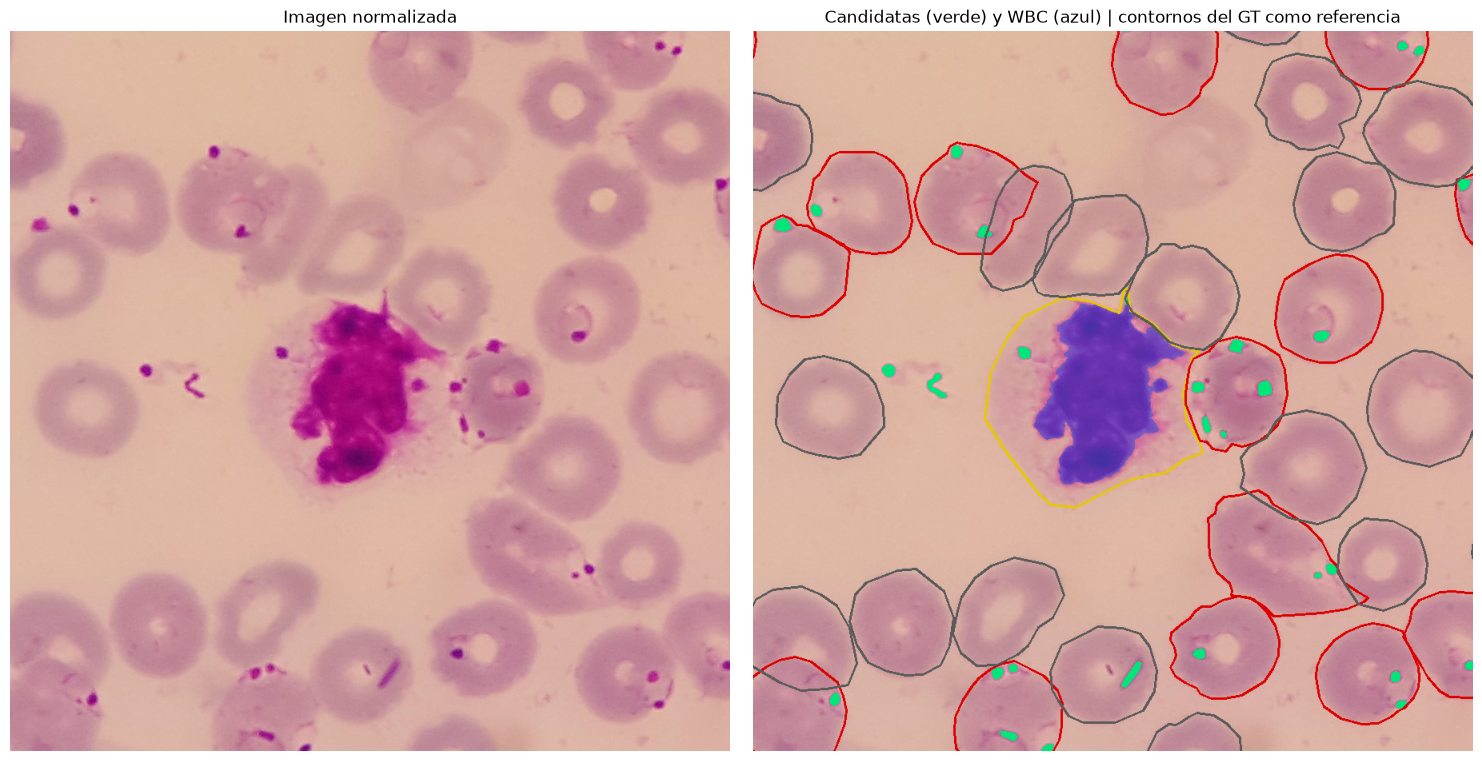

In [15]:
reg = next(r for r in imagenes if r["image_id"] == "IMG_20150819_133447.jpg")  # imagen con parasitadas y glóbulos blancos
img = normalizar_fondo(cargar_imagen(reg["patient_id"], reg["image_id"]), fondos[reg["image_id"]], fondo_ref)
candidatas, wbc = regiones_candidatas(img, **PARAMS_IMAGEN)
anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])

pintada = img.copy()
pintada[wbc] = (0.5 * pintada[wbc] + 0.5 * np.array([40, 90, 230])).astype(np.uint8)
pintada[candidatas] = COLOR_MASCARA
color_gt = {LABEL_PARASITIZED: (220, 0, 0), LABEL_UNINFECTED: (90, 90, 90), LABEL_WBC: (230, 200, 0)}
for a in anot:
    if a["polygon"] is not None:
        cv2.polylines(pintada, [np.round(a["polygon"]).astype(np.int32)], True, color_gt[a["label"]], 2)

# Zona alrededor del primer glóbulo blanco
wbc_gt = next(a for a in anot if a["label"] == LABEL_WBC)
cx, cy = wbc_gt["polygon"].mean(axis=0).astype(int)
mitad = 450
y0, x0 = max(cy - mitad, 0), max(cx - mitad, 0)
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
ax[0].imshow(img[y0:y0 + 2 * mitad, x0:x0 + 2 * mitad])
ax[0].set_title("Imagen normalizada")
ax[1].imshow(pintada[y0:y0 + 2 * mitad, x0:x0 + 2 * mitad])
ax[1].set_title("Candidatas (verde) y WBC (azul) | contornos del GT como referencia")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Qué se ve en la figura:**
- Las candidatas (verde) caen sobre los puntos violetas de las células parasitadas (borde rojo), y casi no aparecen en las sanas (borde gris).
- La máscara de WBC (azul) cubre el **núcleo** del glóbulo blanco pero no su citoplasma, que es mucho más claro. Para excluir el glóbulo blanco **completo**, A3 tiene que extender esta región (por ejemplo, con una dilatación o con la segmentación de la célula que la contiene).
- Las candidatas fuera de los polígonos son sobre todo **objetos oscuros libres entre las células** (parásitos o restos fuera de un eritrocito). A6 no va a encontrar un eritrocito que los contenga, así que tienen que descartarse en ese paso.
- En train, la máscara de WBC cubre los **10 de 10** glóbulos blancos (más del 30 % de su área) y **no da ninguna región** que no sea WBC (con el criterio anterior, solo violeta, daba 7). Es un resultado sobre los mismos datos de train con los que se eligieron los umbrales, así que todavía tiene que confirmarse en la evaluación final.

## 8. Conclusiones de C3

### Detector por célula (para C4 y la segmentación general + color)

1. La máscara de regiones oscuras detecta células parasitadas **mucho mejor** que los estadísticos de color de la célula entera. Con **validación anidada por paciente** (referencia, parámetros y umbral elegidos sin el paciente evaluado), la exactitud balanceada media es **0.951** (peor paciente 0.789), contra ≈0.63 del umbral sobre `G_p5` en C2. La búsqueda exploratoria daba 0.957, así que el resultado no depende de haber elegido la mejor combinación mirando la misma validación.
2. Las manchas son **regiones sospechosas**, no parásitos verificados: el GT no delimita los parásitos, así que lo que se evalúa es la detección de **células** con regiones sospechosas, no la precisión espacial de la máscara.
3. La clave es buscar una **mancha compacta** que sea más oscura que casi todo lo que aparece en células sanas (umbral muy estricto, `q` = 0.05 %) y de **tamaño suficiente** (≥ 50 píxeles).
4. **Parámetros elegidos** (con todo train; en la validación anidada se eligieron casi los mismos en cada vuelta): canal **G**, valor **relativo a la mediana de la célula** (umbral: 39 niveles por debajo de la mediana), erosión de 5 píxeles y área mínima de 50 píxeles. G y b funcionan casi igual; elegimos G porque es el que también usa el Bloque A.
5. Con los parámetros finales aplicados a train quedan **4 parasitadas sin detectar** (de 217) y **40 sanas marcadas** (de 2135). Es un resultado sobre los mismos datos usados para ajustar, así que sirve para interpretar los errores, no para estimar el rendimiento. Mirando la figura:
   - los falsos negativos son parásitos muy tenues o pegados al borde de la célula;
   - los falsos positivos son sobre todo zonas oscuras en el borde, donde la célula se superpone con otra o con algo teñido, y algunos puntos oscuros que podrían ser plaquetas o parásitos no anotados.
6. El **peor paciente** queda en ≈0.79 porque tiene muy pocas parasitadas (5): perder una sola célula baja mucho la sensibilidad.
7. **Para C4:** con esta máscara se pueden calcular características por célula: área de la mayor mancha, cantidad de manchas, proporción de la célula marcada y color medio de las manchas.
8. **Para el Bloque A / integración:** la función `mascara_oscura_violeta` con `PARAMS` se aplica a cada célula segmentada, sobre la imagen normalizada por fondo con `fondo_ref` de train.

### Detector sobre la imagen completa (para el Bloque A)

9. Con un **top-hat negro** sobre G (normalizado por fondo) se detectan las regiones candidatas **sin conocer las células y sin usar el GT**. Con validación anidada por paciente (referencia de normalización, parámetros y umbral elegidos sin el paciente evaluado en la partición externa), la exactitud balanceada a nivel célula es **0.933** (peor paciente 0.791), apenas por debajo del detector por célula. Recalcular la referencia sin el paciente evaluado casi no cambia el resultado, así que la normalización no introduce un sesgo apreciable.
10. **Parámetros finales** (elegidos con los 6 pacientes de train): disco de radio **20 píxeles**, top-hat **> 61** (deja marcado el 0.02 % de los píxeles de eritrocitos sanos) y área mínima de **25 píxeles**. Restringir a la zona de células (Otsu) no cambia el resultado, así que no se usa.
11. **Glóbulos blancos:** se usa el mismo criterio que el pipeline (`color_stain/wbc_detection.py`): regiones **violetas y oscuras** (b < 127 y G < 100) de al menos 6000 píxeles. En train cubren el núcleo de los 10 glóbulos blancos sin ninguna región falsa; el criterio anterior (solo violeta, ≥ 12000 píxeles) daba 7 regiones falsas y tapaba eritrocitos parasitados del paciente 209C68P29N. La máscara marca el **núcleo**: el Bloque A elimina el objeto segmentado entero que lo contiene. Como los umbrales se eligieron con train, el resultado tiene que confirmarse en la evaluación final.
12. **Entrega al Bloque A:** las máscaras de las 12 imágenes de train están en `results/c3_candidatas/`: `{imagen}_candidatas.png` (para la segmentación dirigida, A6) y `{imagen}_wbc.png` (para la exclusión de WBC, A3). El detector está en `color_stain/color_candidates.py` (`detectar_candidatas`), que da exactamente las mismas máscaras que este notebook. **Test no se usó**: en la evaluación final se aplica esa función, sin reajustar nada.
13. Las candidatas que caen fuera de los eritrocitos (≈7 por imagen, sobre todo objetos oscuros libres entre las células) tienen que descartarse en A6, cuando no se encuentra un eritrocito que las contenga.